In [25]:
# Standard library
import os

# Data manipulation and math
import pandas as pd
import numpy as np
from scipy import stats
from scipy.stats import mannwhitneyu

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Survival analysis
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
from lifelines.plotting import add_at_risk_counts

# R to Python integration
import rpy2.robjects as robjects
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter

In [27]:
#TableS1.PatientData.20151020.v3.xlsx is Table S1. of Ceccarelli, Michele, et al.
#"Molecular profiling reveals biologically discrete subsets and pathways of progression in diffuse glioma." 
#Cell 164.3 (2016): 550-563.
# downloadable from https://www.cell.com/cms/10.1016/j.cell.2015.12.028/attachment/92d4425d-44e2-4c91-9ea8-98b58a172a43/mmc2.xlsx
df = pd.read_excel("TableS1.PatientData.20151020.v3.xlsx", skiprows=1)
d_k= pd.read_csv("Dks_7_30_25.csv")

Text(0.05, 0.9, ' r = 0.75\np = 7.45e-20')

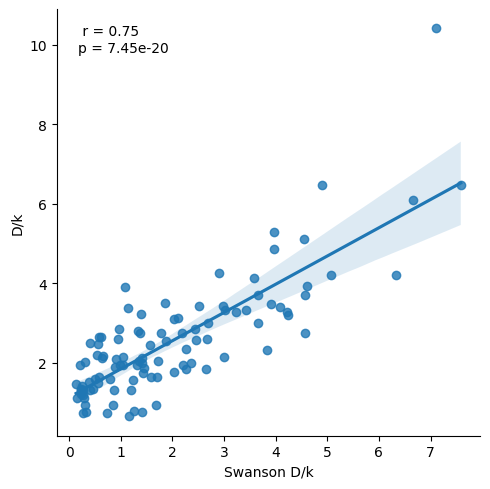

In [28]:
r, p= stats.spearmanr(d_k["Swanson D/k"], d_k["D/k"])
sns.lmplot(x="Swanson D/k", y="D/k", data=d_k);
plt.text(0.05, 0.9, f" r = {r:.2f}\np = {p:.3g}", transform=plt.gca().transAxes)

Text(0.05, 0.9, ' r = 0.20\np = 0.04')

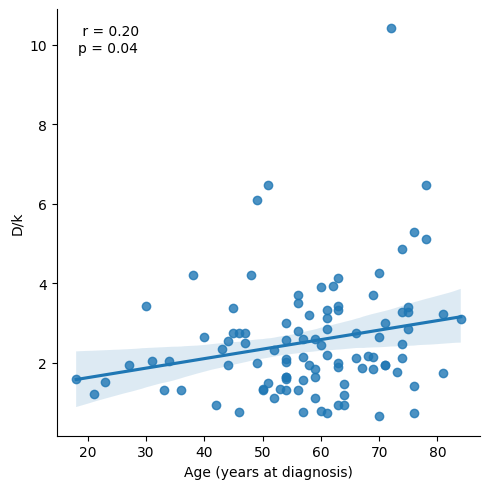

In [29]:
merged = pd.merge(d_k, df, left_on="id", right_on="Case")
r_age, p_age= stats.spearmanr(merged["Age (years at diagnosis)"], merged["D/k"], nan_policy='omit')
sns.lmplot(x="Age (years at diagnosis)", y="D/k", data=merged);
plt.text(0.05, 0.9, f" r = {r_age:.2f}\np = {p_age:.3g}", transform=plt.gca().transAxes)

Text(0.05, 0.9, ' r = 0.17\np = 0.091')

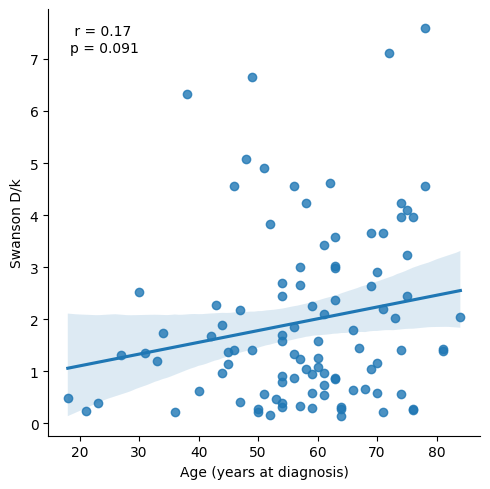

In [32]:
r_age, p_age= stats.spearmanr(merged["Age (years at diagnosis)"], merged["Swanson D/k"], nan_policy='omit')
sns.lmplot(x="Age (years at diagnosis)", y="Swanson D/k", data=merged);
plt.text(0.05, 0.9, f" r = {r_age:.2f}\np = {p_age:.3g}", transform=plt.gca().transAxes)

Text(0.05, 0.9, ' r = -0.20\np = 0.0599')

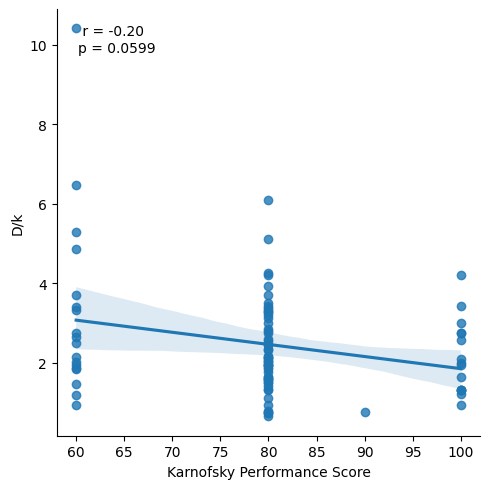

In [34]:
r_perf, p_perf= stats.spearmanr(merged["Karnofsky Performance Score"], merged["D/k"], nan_policy='omit')
sns.lmplot(x="Karnofsky Performance Score", y="D/k", data=merged);
plt.text(0.05, 0.9, f" r = {r_perf:.2f}\np = {p_perf:.3g}", transform=plt.gca().transAxes)

Text(0.05, 0.9, ' r = -0.07\np = 0.516')

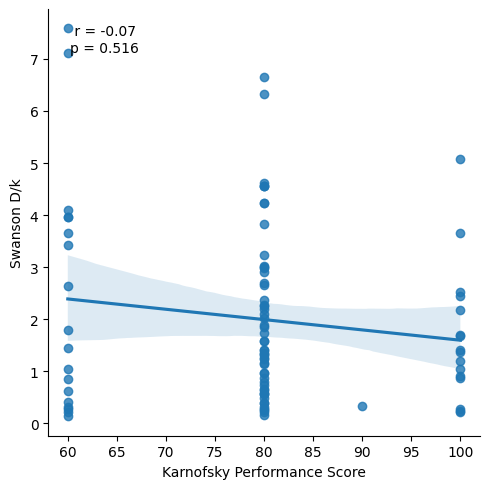

In [36]:
r_perf, p_perf= stats.spearmanr(merged["Karnofsky Performance Score"], merged["Swanson D/k"], nan_policy='omit')
sns.lmplot(x="Karnofsky Performance Score", y="Swanson D/k", data=merged);
plt.text(0.05, 0.9, f" r = {r_perf:.2f}\np = {p_perf:.3g}", transform=plt.gca().transAxes)

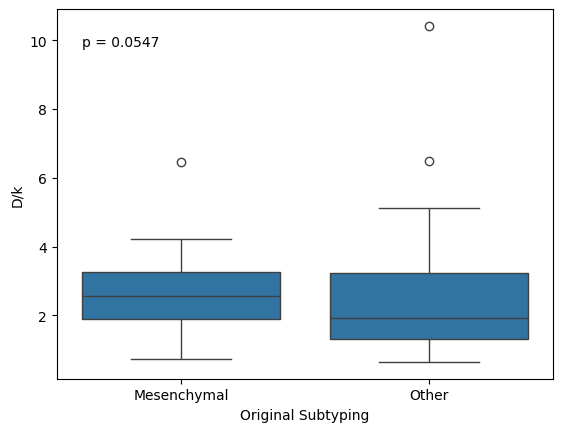

In [49]:
merged2=merged.copy(deep=True)
merged2 = merged2.dropna(subset=["Original Subtype"])
merged2 = merged2[merged2["Original Subtype"] != "Neural"]
merged2["Original Subtype"] = merged2["Original Subtype"].where(merged2["Original Subtype"] == "Mesenchymal", "Other")
group1 = merged2.loc[merged2["Original Subtype"] == "Mesenchymal", "D/k"]
group2 = merged2.loc[merged2["Original Subtype"] == "Other", "D/k"]

stat, p_value = mannwhitneyu(group1, group2, alternative='greater')  # or 'greater' / 'less'
sns.boxplot(x="Original Subtype", y="D/k", data=merged2)
plt.xlabel("Original Subtyping")
plt.text(0.05, 0.9, f"p = {p_value:.3g}", transform=plt.gca().transAxes)
plt.savefig("original_subtyping.pdf", bbox_inches="tight")
plt.show()

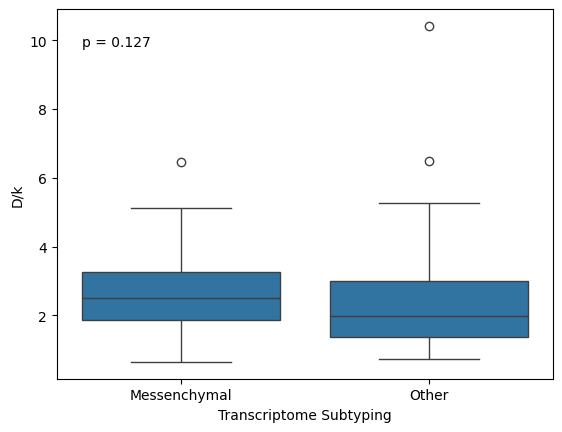

In [40]:
merged5 = merged.copy(deep=True)
merged5 = merged5.dropna(subset=["Transcriptome Subtype"])
merged5 = merged5[merged5["Transcriptome Subtype"] != "NE"]

merged5["Transcriptome Subtype"] = merged5["Transcriptome Subtype"].where(merged5["Transcriptome Subtype"] == "ME", "Other")
merged5["Transcriptome Subtype"] = merged5["Transcriptome Subtype"].replace({"ME": "Messenchymal"})

group1 = merged5.loc[merged5["Transcriptome Subtype"] == "Messenchymal", "D/k"]
group2 = merged5.loc[merged5["Transcriptome Subtype"] == "Other", "D/k"]

stat, p_value = mannwhitneyu(group1, group2, alternative='greater') 
sns.boxplot(x="Transcriptome Subtype", y="D/k", data=merged5)
plt.xlabel("Transcriptome Subtyping")
plt.text(0.05, 0.9, f"p = {p_value:.3g}", transform=plt.gca().transAxes)
plt.savefig("transcriptome_subtyping.pdf", bbox_inches="tight")

plt.show()


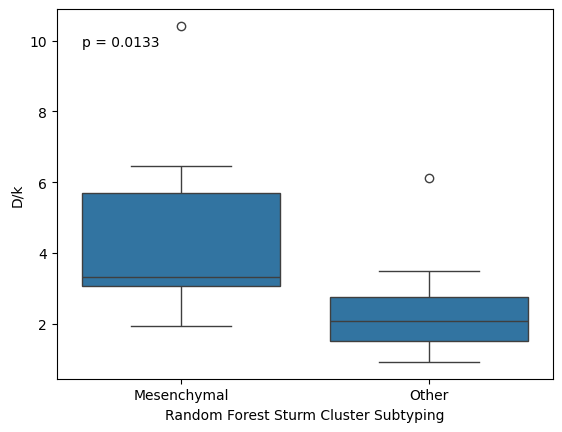

In [43]:
merged4=merged.copy(deep=True)
merged4 = merged4.dropna(subset=["Random Forest Sturm Cluster"])
merged4["Random Forest Sturm Cluster"] = merged4["Random Forest Sturm Cluster"].where(merged4["Random Forest Sturm Cluster"] == "Mesenchymal", "Other")
group1 = merged4.loc[merged4["Random Forest Sturm Cluster"] == "Mesenchymal", "D/k"]
group2 = merged4.loc[merged4["Random Forest Sturm Cluster"] == "Other", "D/k"]

# Mann-Whitney U test (Wilcoxon rank-sum)
stat, p_value = mannwhitneyu(group1, group2, alternative='greater')  # or 'greater' / 'less'
#print(f"Mann-Whitney U statistic = {stat:.3f}, p-value = {p_value:.4f}")
sns.boxplot(x="Random Forest Sturm Cluster", y="D/k", data=merged4)
plt.xlabel("Random Forest Sturm Cluster Subtyping")

plt.text(0.05, 0.9, f"p = {p_value:.3g}", transform=plt.gca().transAxes)
plt.savefig("randomforest_subtyping.pdf", bbox_inches="tight")

plt.show()

Asking R to find the optimal cutpoint for D/k...
Optimal cutpoint found by R (maxstat): 2.081


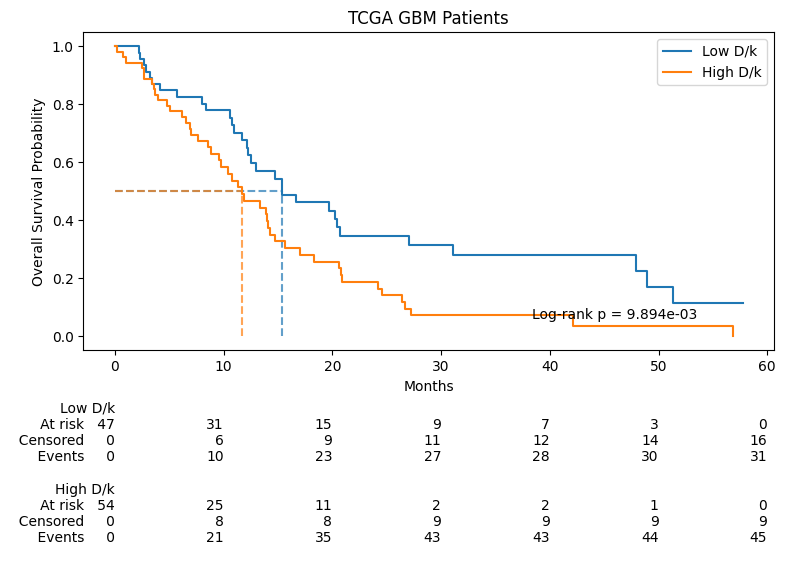

In [45]:
def plot_survival_by_maxstat(df, variable_name, time_col='Survival (months)', event_col='Vital status (1=dead)', title="TCGA GBM Patients"):
    
    # 1. Clean the data
    merged_clean = df.copy(deep=True)
    merged_clean = merged_clean.dropna(subset=[time_col, event_col, variable_name])
    merged_clean[time_col] = pd.to_numeric(merged_clean[time_col])
    merged_clean[event_col] = pd.to_numeric(merged_clean[event_col])

    # 2. Prepare a simplified dataframe for R
    r_df_pandas = merged_clean[[time_col, event_col, variable_name]].copy()
    r_df_pandas.columns = ['time', 'event', 'marker']

    # 3 & 4. Run the R script using the modern context manager
    print(f"Asking R to find the optimal cutpoint for {variable_name}...")
    
    r_script = """
    library(survminer)
    # Run the maxstat algorithm
    res <- surv_cutpoint(r_df, time="time", event="event", variables="marker")
    # Extract just the numeric cutpoint value
    optimal_cutpoint <- summary(res)[1, "cutpoint"]
    optimal_cutpoint
    """
    
    with localconverter(robjects.default_converter + pandas2ri.converter):
        # Push the pandas dataframe into R's global environment
        robjects.globalenv['r_df'] = robjects.conversion.py2rpy(r_df_pandas)
        
        # Execute the R script and grab the result
        best_cutpoint_array = robjects.r(r_script)
        best_cutpoint = best_cutpoint_array[0] 
        
    print(f"Optimal cutpoint found by R (maxstat): {best_cutpoint:.3f}")

    # 5. Apply the cutpoint back to  Python data
    T = merged_clean[time_col]
    E = merged_clean[event_col]
    variable = merged_clean[variable_name]
    
    group_low = (variable <= best_cutpoint)
    group_high = (variable > best_cutpoint)

    # Run the log-rank test
    results = logrank_test(T[group_low], T[group_high], E[group_low], E[group_high])
    p_value = results.p_value

    group_col = f"{variable_name}_Group"
    merged_clean[group_col] = np.where(group_low, f"Low {variable_name}", f"High {variable_name}")

    # 6. Plotting using lifelines
    group_labels = [f"Low {variable_name}", f"High {variable_name}"]
    kmf_dict = {label: KaplanMeierFitter() for label in group_labels}

    plt.figure(figsize=(8, 6))
    ax = plt.subplot(111)
    colors = ['tab:blue', 'tab:orange']  
    
    for i, label in enumerate(group_labels):
        data = merged_clean[merged_clean[group_col] == label]
        kmf = kmf_dict[label]
        kmf.fit(durations=data[time_col], event_observed=data[event_col], label=label)
        kmf.plot(ax=ax, ci_show=False, color=colors[i])

        median = kmf.median_survival_time_
        if not np.isnan(median) and not np.isinf(median):
            ax.plot([median, median], [0, 0.5], color=colors[i], linestyle='--', alpha=0.7)
            ax.plot([0, median], [0.5, 0.5], color=colors[i], linestyle='--', alpha=0.7)

    plt.text(0.65, 0.1, f"Log-rank p = {p_value:.3e}", transform=ax.transAxes)
    plt.title(title)
    plt.xlabel("Months")
    plt.ylabel("Overall Survival Probability")

    add_at_risk_counts(*[kmf_dict[label] for label in group_labels], ax=ax, fontsize=10)
    plt.tight_layout()
    plt.show()

# Run it like this:
plot_survival_by_maxstat(merged, variable_name="D/k")

Asking R to find the optimal cutpoint for Swanson D/k...
Optimal cutpoint found by R (maxstat): 3.651


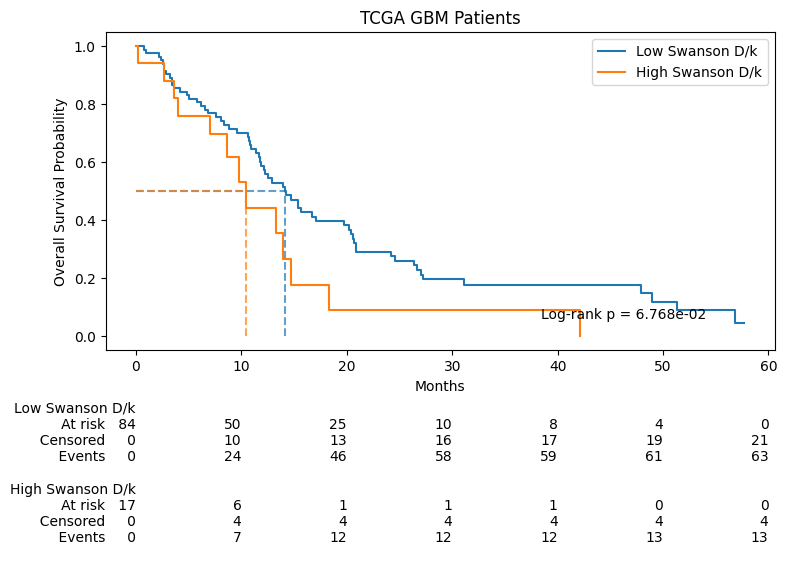

In [47]:
plot_survival_by_maxstat(merged, variable_name="Swanson D/k")